# NLP Assignment 2 — Word representations for GoEmotions
**Phase 2 · Parts A–D: count-based representations, Word2Vec / fastText, probing, and packaging**

Team: *add names / IDs here* · Course: *add course / section* · Date: *add date*

**Topic recap.** Fine-grained emotion detection on Reddit comments (GoEmotions: 54,263 comments, 28 emotion labels). Phase 1 produced a cleaned corpus; here we turn that corpus into numbers a model can use, and compare the ways of doing it.

| Part | Sections | Content |
|---|---|---|
| **A** | A1 – A4 | Bag of Words, TF-IDF, n-grams, and a hand-worked numerical example |
| **B** | B1 – B4 | Word2Vec (CBOW and Skip-gram) and fastText |
| **C** | C1 – C4 | similar words, similarity scores, an analogy, and count-based vs learned |
| **D** | D1 – D2 | saving every model once, and the `vectorize()` interface for Phase 3 |

**Decisions that apply to everything below** (they keep the comparison fair, as the brief requires):

1. **One corpus.** Every representation is built from the Phase 1 column `text_clean`. We do *not* clean anything differently.
2. **Fitted on the training split only.** Vocabulary, IDF values and embeddings come from the 43,410 training comments. Validation and test comments are only ever *transformed*, so Phase 3 can be evaluated without leakage.
3. **Phase 1 tokens are kept as they are.** `text_clean` is already tokenised (words separated by single spaces), so every vectorizer simply splits on whitespace. A library tokenizer would silently drop one-letter words such as `i`, signal tokens such as `!` and `?`, placeholders such as `<name>` and emoji, all of which Phase 1 deliberately kept.
4. **Identical hyper-parameters** for CBOW, Skip-gram and fastText; only the training scheme (and, for fastText, the sub-word information) differs.
5. **Deterministic.** Fixed seed, one worker thread and a process-independent hash: re-running gives the same vectors.

All reusable code lives in `src/` (`representations.py`, `build_representations.py`, `vectorize.py`); this notebook calls it, so it shows exactly what the scripts do.

In [1]:
import sys, re, time, json, math, subprocess, collections, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 160)

def find_project_root():
    """Locate the folder that contains src/cleaning.py, wherever Jupyter was started."""
    start = Path.cwd().resolve()
    for base in (start, *start.parents):
        for candidate in (base, base / "goemotions-nlp"):
            if (candidate / "src" / "cleaning.py").exists():
                return candidate
    raise FileNotFoundError(
        f"Could not find the project's src/ folder from {start}.\n"
        "This notebook needs the whole project, not just the .ipynb file: clone the repository "
        "(or unzip goemotions-nlp.zip) and open notebooks/03_word_representations.ipynb from inside it "
        "(on Colab/Kaggle, clone or upload the project, then %cd goemotions-nlp/notebooks first)."
    )

ROOT = find_project_root()
sys.path.insert(0, str(ROOT))

from src import representations as R

def say(text):
    """Show a sentence (with numbers computed by the code above it) as formatted text."""
    display(Markdown(text))

if not R.CLEAN_CSV.exists():
    print("Phase 1 output not found - running  python -m src.run_cleaning  ...")
    subprocess.run([sys.executable, "-m", "src.run_cleaning"], cwd=ROOT, check=True)

df = R.load_clean_corpus()
train = df[df["split"] == R.FIT_SPLIT]
texts = train["text_clean"].tolist()
sentences = R.tokenize_corpus(texts)
word_counts = collections.Counter(w for s in sentences for w in s)
N_DOCS, N_TOKENS = len(texts), sum(word_counts.values())

summary = df.groupby("split").agg(comments=("text_clean", "size"),
                                  tokens=("text_clean", lambda s: s.str.split().str.len().sum()))
summary.loc["fitted on 'train'"] = ["", ""]
display(summary.loc[["train", "validation", "test"]])
say(f"**Corpus used to fit every representation:** the *{R.FIT_SPLIT}* split — {N_DOCS:,} comments, "
    f"{N_TOKENS:,} tokens, {len(word_counts):,} distinct words, {N_TOKENS / N_DOCS:.1f} tokens per comment on average.")

,comments,tokens
split,,
train,43410,380557
validation,5426,47457
test,5427,47255


**Corpus used to fit every representation:** the *train* split — 43,410 comments, 380,557 tokens, 20,026 distinct words, 8.8 tokens per comment on average.

### A note on corpus size (it matters for Part B)

About 380 thousand training tokens is a **very small corpus** for learning word embeddings. The original Word2Vec and fastText papers train on billions of words, and the usual advice is that embeddings need at least millions. We therefore expect noisy vectors for all but the commonest words, and we interpret the neighbours and similarity scores in Parts B and C cautiously instead of claiming more than the data supports.

---
# Part A — Count-based representations

A count-based representation describes a document by *which words it contains* (and how often). It has one dimension per vocabulary entry, so the vectors are long but almost entirely zeros.

## A1  Bag of Words

A **bag of words** keeps only how many times each word occurs in a comment and forgets the order. Stacking one such count vector per comment gives the **document–term matrix** (rows = comments, columns = vocabulary). We build it with scikit-learn's `CountVectorizer`, told to split on whitespace and not to lower-case again (Phase 1 already did).

In [2]:
bow = R.make_count_vectorizer()
X_bow = bow.fit_transform(texts)

n_docs, n_terms = X_bow.shape
n_cells = n_docs * n_terms
sparsity_bow = R.sparsity_pct(X_bow)
sparse_mb = (X_bow.data.nbytes + X_bow.indices.nbytes + X_bow.indptr.nbytes) / 1e6
dense_gb = n_cells * X_bow.dtype.itemsize / 1e9

display(pd.DataFrame({
    "shape (comments × words)": [f"{n_docs:,} × {n_terms:,}"],
    "cells": [f"{n_cells:,}"],
    "non-zero cells": [f"{X_bow.nnz:,}"],
    "zero cells (sparsity)": [f"{sparsity_bow:.4f} %"],
    "stored sparse": [f"{sparse_mb:.1f} MB"],
    "if stored dense": [f"{dense_gb:.1f} GB"],
}, index=["Bag of Words"]).T)

i = 0
row = X_bow[i]
vocab_terms = bow.get_feature_names_out()
print("comment      :", texts[i])
print("non-zero cols:", {vocab_terms[j]: int(c) for j, c in zip(row.indices, row.data)})

top = pd.Series(np.asarray(X_bow.sum(axis=0)).ravel(), index=vocab_terms).sort_values(ascending=False)
print("\n15 most frequent words in the matrix (total count):")
display(top.head(15).to_frame("count").T)

,Bag of Words
shape (comments × words),"43,410 × 20,026"
cells,"869,328,660"
non-zero cells,"356,917"
zero cells (sparsity),99.9589 %
stored sparse,3.0 MB
if stored dense,3.5 GB


comment      : my favourite food anything i not cook myself
non-zero cols: {'my': 1, 'favourite': 1, 'food': 1, 'anything': 1, 'i': 1, 'not': 1, 'cook': 1, 'myself': 1}

15 most frequent words in the matrix (total count):


,i,you,not,<name>,!,?,<num>,my,get,so,like,just,...,what,would
count,23946,11553,10594,7680,7185,5132,5026,3781,3662,3502,3452,3430,2945,2773,2744


In [3]:
say(f"**Result.** The Bag-of-Words matrix is **{n_docs:,} × {n_terms:,}**; only {X_bow.nnz:,} of its {n_cells:,} cells are non-zero, "
    f"so it is **{sparsity_bow:.3f} % zeros**. A typical comment uses only {X_bow.nnz / n_docs:.1f} distinct words out of {n_terms:,}. "
    f"Stored as a sparse matrix it needs {sparse_mb:.1f} MB; stored densely it would need about {dense_gb:.1f} GB, which is why "
    f"count-based features are always kept in a sparse format.")

**Result.** The Bag-of-Words matrix is **43,410 × 20,026**; only 356,917 of its 869,328,660 cells are non-zero, so it is **99.959 % zeros**. A typical comment uses only 8.2 distinct words out of 20,026. Stored as a sparse matrix it needs 3.0 MB; stored densely it would need about 3.5 GB, which is why count-based features are always kept in a sparse format.

## A2  TF-IDF

Raw counts treat every word as equally informative, so `not` or `i` (present in a large share of all comments) outweighs a distinctive word that appears once. **TF-IDF** re-weights each count:

$$\text{tf-idf}(t,d)=\text{tf}(t,d)\times \text{idf}(t),\qquad \text{idf}(t)=\ln\frac{1+N}{1+\text{df}(t)}+1$$

* **tf(t, d)** — how often term *t* occurs in document *d* (the Bag-of-Words count).
* **df(t)** — in how many of the *N* documents *t* occurs at least once. 
* **idf(t)** — large when *t* is rare, small when it is everywhere. This is scikit-learn's *smoothed* version; the textbook version is simply ln(N / df).
* Each row is finally divided by its own length (L2 norm), so a long comment does not get bigger numbers than a short one.

The next cell builds the matrix over the same corpus and shows one real comment with a few high-weight and several low-weight words.

In [4]:
tfidf = R.make_tfidf_vectorizer()
X_tfidf = tfidf.fit_transform(texts)
assert X_tfidf.shape == X_bow.shape

terms = np.array(tfidf.get_feature_names_out())
term_index = {t: j for j, t in enumerate(terms)}
doc_freq = np.asarray((X_bow > 0).sum(axis=0)).ravel()
idf_textbook = np.log(N_DOCS / doc_freq)
idf_sklearn = tfidf.idf_

order = np.argsort(idf_sklearn)
extremes = pd.DataFrame({
    "df": doc_freq[order], "df %": (100 * doc_freq[order] / N_DOCS).round(2),
    "idf (textbook)": idf_textbook[order].round(2), "idf (sklearn)": idf_sklearn[order].round(2)},
    index=terms[order])
print("Lowest idf = the most common words:");  display(extremes.head(8).T)
print("Highest idf = words seen in only one comment (a few of the", int((doc_freq == 1).sum()), "):"); display(extremes.tail(4).T)

rng = np.random.default_rng(R.SEED)
example = None
for i in rng.permutation(N_DOCS):
    toks = sentences[i]
    dfs = [doc_freq[term_index[t]] for t in set(toks)]
    if 8 <= len(toks) <= 12 and max(dfs) / N_DOCS >= 0.05 and min(dfs) <= 5:
        example = i
        break

tokens = list(dict.fromkeys(sentences[example]))
row = X_tfidf[example]
weights = {terms[j]: w for j, w in zip(row.indices, row.data)}
table = pd.DataFrame({
    "tf": [sentences[example].count(t) for t in tokens],
    "df": [doc_freq[term_index[t]] for t in tokens],
    "idf (textbook)": [round(idf_textbook[term_index[t]], 2) for t in tokens],
    "idf (sklearn)": [round(idf_sklearn[term_index[t]], 2) for t in tokens],
    "tf-idf weight": [round(weights[t], 3) for t in tokens]}, index=tokens).sort_values("tf-idf weight", ascending=False)
print("\nraw comment   :", train.iloc[example]["text"])
print("cleaned (A2)  :", texts[example])
display(table)
print("row length (L2 norm of the weights):", round(float(np.linalg.norm(row.data)), 3))

Lowest idf = the most common words:


,i,not,you,<name>,!,?,<num>,get
df,17355.00,9538.00,9275.00,6059.00,6020.00,4581.00,3682.00,3483.00
df %,39.98,21.97,21.37,13.96,13.87,10.55,8.48,8.02
idf (textbook),0.92,1.52,1.54,1.97,1.98,2.25,2.47,2.52
idf (sklearn),1.92,2.52,2.54,2.97,2.98,3.25,3.47,3.52


Highest idf = words seen in only one comment (a few of the 9961 ):


,🦵,aaf,🧡,aaditi
df,1.00,1.00,1.00,1.00
df %,0.00,0.00,0.00,0.00
idf (textbook),10.68,10.68,10.68,10.68
idf (sklearn),10.99,10.99,10.99,10.99



raw comment   : I would say they do because it was a horrible accident but they were also in the wrong. The military tried to get them to disperse they didnt.
cleaned (A2)  : i would say horrible accident also wrong military try get disperse not


,tf,df,idf (textbook),idf (sklearn),tf-idf weight
disperse,1,1,10.68,10.99,0.521
military,1,29,7.31,8.28,0.393
accident,1,31,7.24,8.21,0.390
horrible,1,124,5.86,6.85,0.325
wrong,1,370,4.76,5.76,0.273
also,1,687,4.15,5.14,0.244
try,1,840,3.95,4.94,0.235
say,1,1453,3.40,4.40,0.209
would,1,2579,2.82,3.82,0.181
get,1,3483,2.52,3.52,0.167


row length (L2 norm of the weights): 1.0


**Reading the table.**

* **High weight — rare, specific words.** A word that few other comments use (small `df`, so large idf) dominates the comment's vector. It is the part of the comment that tells it apart from the rest of the corpus, which is what a classifier can use.
* **Weight pushed down — common words.** Words that occur in a large share of all comments (`i`, `not`, `you`, and signal tokens such as `!`) have a small idf, so even when they occur often in the comment they contribute little. TF-IDF therefore down-weights exactly the words that carry the least information about *this* comment.
* **"Toward zero" needs a caveat.** With the textbook formula ln(N/df) a word present in *every* document would get exactly 0. In this corpus nothing is that common (the commonest word, `i`, is in about 40 % of the comments, because Phase 1 already removed stop words), so no weight is literally zero; the common words are only *relatively* small. scikit-learn also adds `+1` to the idf so that a word seen everywhere keeps a small positive weight instead of vanishing. Section A4 uses a tiny corpus in which one word *is* in every document, so you can see both formulas side by side.

## A3  N-grams

A unigram model cannot tell `not good` from `good`: the negation and the word are counted separately. **N-grams** add short runs of consecutive words as extra features: bigrams (2 words) and trigrams (3 words). The price is a much bigger vocabulary. We rebuild the Bag of Words with `ngram_range = (1,1)`, `(1,2)` and `(1,3)`, with no pruning (`min_df=1`) and with pruning (`min_df=2` and `5`, which drop n-grams seen in fewer than 2 or 5 comments).

,n-grams,min_df,features,non-zeros,sparsity %,non-zeros / comment,sparse size MB
0,unigrams,1,20026,356917,99.9589,8.2,3.0
1,unigrams,2,10065,346956,99.9206,8.0,2.9
2,unigrams,5,5122,333903,99.8498,7.7,2.8
3,uni + bigrams,1,199440,691992,99.9920,15.9,5.7
4,uni + bigrams,2,40326,532878,99.9696,12.3,4.4
5,uni + bigrams,5,12565,463417,99.9150,10.7,3.9
6,uni + bi + trigrams,1,458858,985445,99.9951,22.7,8.1
7,uni + bi + trigrams,2,53138,579725,99.9749,13.4,4.8
8,uni + bi + trigrams,5,14408,484093,99.9226,11.2,4.0


,1-grams only,2-grams only,3-grams only
distinct features (min_df=1),20026,179414,259418


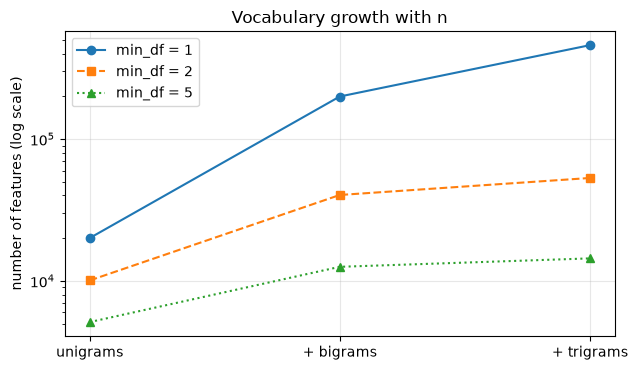

most frequent bigrams: 'i not' (2,239), 'i think' (1,038), 'thank you' (978), 'i love' (939), 'i would' (937), 'you not' (750), 'i just' (646), '<num> <num>' (644), '! i' (575), '<name> <name>' (556)


most frequent trigrams: 'i not know' (249), 'i not think' (219), 'thank you !' (183), '<num> <num> <num>' (174), 'i feel like' (146), 'i would love' (141), '<num> year old' (119), 'i think i' (118), 'i hope you' (116), 'i think you' (106)


In [5]:
rows = []
for ng, label in [((1, 1), "unigrams"), ((1, 2), "uni + bigrams"), ((1, 3), "uni + bi + trigrams")]:
    for min_df in (1, 2, 5):
        v = R.make_count_vectorizer(ngram_range=ng, min_df=min_df)
        X = v.fit_transform(texts)
        rows.append({"n-grams": label, "min_df": min_df, "features": X.shape[1], "non-zeros": X.nnz,
                     "sparsity %": round(R.sparsity_pct(X), 4), "non-zeros / comment": round(X.nnz / X.shape[0], 1),
                     "sparse size MB": round((X.data.nbytes + X.indices.nbytes + X.indptr.nbytes) / 1e6, 1)})
growth = pd.DataFrame(rows)
display(growth)

pure = {}
for n in (1, 2, 3):
    pure[f"{n}-grams only"] = len(R.make_count_vectorizer(ngram_range=(n, n)).fit(texts).vocabulary_)
display(pd.Series(pure, name="distinct features (min_df=1)").to_frame().T)

fig, ax = plt.subplots(figsize=(6.5, 3.8))
for min_df, style in [(1, "o-"), (2, "s--"), (5, "^:")]:
    sub = growth[growth.min_df == min_df]
    ax.plot([1, 2, 3], sub["features"], style, label=f"min_df = {min_df}")
ax.set_yscale("log"); ax.set_xticks([1, 2, 3], ["unigrams", "+ bigrams", "+ trigrams"])
ax.set_ylabel("number of features (log scale)"); ax.set_title("Vocabulary growth with n"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

for n, name in [(2, "bigrams"), (3, "trigrams")]:
    v = R.make_count_vectorizer(ngram_range=(n, n)); Xn = v.fit_transform(texts)
    counts = pd.Series(np.asarray(Xn.sum(axis=0)).ravel(), index=v.get_feature_names_out()).sort_values(ascending=False)
    print(f"most frequent {name}:", ", ".join(f"'{g}' ({c:,})" for g, c in counts.head(10).items()))

In [6]:
g = growth.set_index(["n-grams", "min_df"])
uni, bi, tri = (g.loc[(k, 1), "features"] for k in ["unigrams", "uni + bigrams", "uni + bi + trigrams"])
say(f"**Result.** Without pruning, the vocabulary grows from **{uni:,}** unigrams to **{bi:,}** features with bigrams (×{bi/uni:.1f}) "
    f"and **{tri:,}** with trigrams (×{tri/uni:.1f}). With `min_df=2` the trigram model shrinks to {g.loc[('uni + bi + trigrams', 2), 'features']:,} features "
    f"({100 * (1 - g.loc[('uni + bi + trigrams', 2), 'features'] / tri):.0f} % fewer), because most n-grams occur in a single comment.")

**Result.** Without pruning, the vocabulary grows from **20,026** unigrams to **199,440** features with bigrams (×10.0) and **458,858** with trigrams (×22.9). With `min_df=2` the trigram model shrinks to 53,138 features (88 % fewer), because most n-grams occur in a single comment.

**Sparsity trade-off.**

* **The matrix gets sparser, but each row gets fuller.** The percentage of zeros rises with n because the number of columns explodes much faster than the number of entries. But a comment of *k* tokens contains *k* unigrams, *k−1* bigrams and *k−2* trigrams, so the number of **non-zeros per comment** grows too. Memory follows the number of non-zeros, not the percentage of zeros.
* **Most new features are one-offs.** The unpruned bigram and trigram vocabularies are dominated by combinations seen once. A feature seen once cannot help a model generalise (it can only memorise a single training comment), and in a test comment it will rarely reappear. This is why `min_df` pruning is standard: it removes most of the columns and costs few non-zeros.
* **What we gain.** Bigrams recover a little word order, for example negation (`not good`) and polite formulas (`thank you`), which a bag of unigrams scatters. Once rare n-grams are pruned, trigrams add far fewer features than bigrams do (compare the three `min_df=2` rows of the table), because our comments are short (about 9 tokens after cleaning) and rarely repeat the same three-word sequence.
* **Our choice for Phase 3:** the saved TF-IDF vectorizer uses unigrams + bigrams with `min_df=3` (a compact vocabulary that keeps the useful bigrams).

## A4  Hand-worked numerical example

To be sure we understand what the library does, we compute one TF-IDF weight and one bigram **by hand** on a tiny sub-sample, then compare with scikit-learn. The four documents are real short comments from the training set (their Phase 1 `text_clean`), chosen so that the word `good` occurs in all four, the bigram `not good` in three, and one comment repeats a word (`sound` twice).

The "by hand" part uses nothing but `math.log`, counting, and the formulas above, and prints every step so it can be copied onto paper (the assignment asks for a scanned copy of the handwritten version; the printout below is the worksheet to copy from).

In [7]:
toy_ids = ["eezjbs8", "edk3yt2", "ed4qthk", "ed3zhy2"]
toy = df.set_index("comment_id").loc[toy_ids, ["text", "text_clean"]]
toy.index = [f"d{k}" for k in range(1, 5)]
display(toy)

toy_docs = toy["text_clean"].tolist()
toy_tokens = [d.split() for d in toy_docs]
N_TOY = len(toy_docs)
print("N =", N_TOY, "documents")

,text,text_clean
d1,Uhhhhhhhhh well that's not good,uhh well not good
d2,ESPN and sports is not a good combination.,espn sport not good combination
d3,This was so good I groaned audibly.,so good i groan audibly
d4,"Not a good sound, a glorious sound.",not good sound glorious sound


N = 4 documents


In [8]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

def tfidf_by_hand(term, doc_no, docs):
    """Print each step of the scikit-learn TF-IDF weight of `term` in document number `doc_no` (1-based).
    `docs` is a list of token lists (words for a unigram weight, 'w1 w2' strings for a bigram weight)."""
    N = len(docs)
    d = docs[doc_no - 1]
    df_of = lambda t: sum(t in doc for doc in docs)
    idf_of = lambda t: math.log((1 + N) / (1 + df_of(t))) + 1

    tf = d.count(term)
    print(f"term = '{term}', document d{doc_no} = {d}")
    print(f"1) tf       : '{term}' occurs {tf} time(s) in d{doc_no}  ->  tf = {tf}")
    print(f"2) df       : '{term}' occurs in {df_of(term)} of the N = {N} documents  ->  df = {df_of(term)}")
    print(f"3) idf      : ln((1+N)/(1+df)) + 1 = ln({1+N}/{1+df_of(term)}) + 1 = {math.log((1+N)/(1+df_of(term))):.4f} + 1 = {idf_of(term):.4f}")
    print(f"             (the textbook ln(N/df) = ln({N}/{df_of(term)}) = {math.log(N/df_of(term)):.4f})")
    print(f"4) raw      : tf × idf = {tf} × {idf_of(term):.4f} = {tf * idf_of(term):.4f}")

    uniq = list(dict.fromkeys(d))
    raw = {t: d.count(t) * idf_of(t) for t in uniq}
    print(f"5) the same for every term of d{doc_no}:")
    for t in uniq:
        print(f"     {t:16s} tf={d.count(t)}  df={df_of(t)}  idf={idf_of(t):.4f}  raw={raw[t]:.4f}")
    sq = sum(v * v for v in raw.values())
    norm = math.sqrt(sq)
    print(f"6) L2 norm  : sqrt({' + '.join(f'{v:.4f}²' for v in raw.values())}) = sqrt({sq:.4f}) = {norm:.4f}")
    weight = raw[term] / norm
    print(f"7) weight   : raw / norm = {raw[term]:.4f} / {norm:.4f} = {weight:.4f}")
    return weight

by_hand = tfidf_by_hand("sound", 4, toy_tokens)

lib = TfidfVectorizer(tokenizer=str.split, token_pattern=None, lowercase=False)
X_toy = lib.fit_transform(toy_docs)
library_value = X_toy[3, lib.vocabulary_["sound"]]
print(f"\nscikit-learn TfidfVectorizer gives {library_value:.4f}   ->   matches the hand calculation: {math.isclose(by_hand, library_value, rel_tol=1e-9)}")
assert math.isclose(by_hand, library_value, rel_tol=1e-9)

term = 'sound', document d4 = ['not', 'good', 'sound', 'glorious', 'sound']
1) tf       : 'sound' occurs 2 time(s) in d4  ->  tf = 2
2) df       : 'sound' occurs in 1 of the N = 4 documents  ->  df = 1
3) idf      : ln((1+N)/(1+df)) + 1 = ln(5/2) + 1 = 0.9163 + 1 = 1.9163
             (the textbook ln(N/df) = ln(4/1) = 1.3863)
4) raw      : tf × idf = 2 × 1.9163 = 3.8326
5) the same for every term of d4:
     not              tf=1  df=3  idf=1.2231  raw=1.2231
     good             tf=1  df=4  idf=1.0000  raw=1.0000
     sound            tf=2  df=1  idf=1.9163  raw=3.8326
     glorious         tf=1  df=1  idf=1.9163  raw=1.9163
6) L2 norm  : sqrt(1.2231² + 1.0000² + 3.8326² + 1.9163²) = sqrt(20.8569) = 4.5669
7) weight   : raw / norm = 3.8326 / 4.5669 = 0.8392

scikit-learn TfidfVectorizer gives 0.8392   ->   matches the hand calculation: True


In [9]:
t = "good"
print(f"'{t}' occurs in {sum(t in d for d in toy_tokens)} of {N_TOY} documents:  textbook ln(N/df) = ln({N_TOY}/{N_TOY}) = {math.log(1):.1f},"
      f"  scikit-learn ln((1+N)/(1+df)) + 1 = ln({1+N_TOY}/{1+N_TOY}) + 1 = {math.log(1) + 1:.1f}")
print(f"its weight in d4 is {X_toy[3, lib.vocabulary_[t]]:.4f}, against {X_toy[3, lib.vocabulary_['sound']]:.4f} for 'sound'")

'good' occurs in 4 of 4 documents:  textbook ln(N/df) = ln(4/4) = 0.0,  scikit-learn ln((1+N)/(1+df)) + 1 = ln(5/5) + 1 = 1.0
its weight in d4 is 0.2190, against 0.8392 for 'sound'


In [10]:
def bigrams(tokens):
    return [f"{a} {b}" for a, b in zip(tokens, tokens[1:])]

toy_bigrams = [bigrams(t) for t in toy_tokens]
for k, b in enumerate(toy_bigrams, 1):
    print(f"d{k} bigrams: {b}")

target = "not good"
by_hand_counts = [b.count(target) for b in toy_bigrams]
print(f"\ncount of the bigram '{target}' in d1..d4 by hand: {by_hand_counts}")

cv2 = CountVectorizer(tokenizer=str.split, token_pattern=None, lowercase=False, ngram_range=(2, 2))
C2 = cv2.fit_transform(toy_docs)
library_counts = C2[:, cv2.vocabulary_[target]].toarray().ravel().tolist()
print(f"CountVectorizer(ngram_range=(2,2)) gives                  : {library_counts}   ->   matches: {by_hand_counts == library_counts}")
assert by_hand_counts == library_counts

print("\n--- and its TF-IDF weight in d4, with the same seven steps (now the 'terms' are bigrams):\n")
by_hand_bi = tfidf_by_hand(target, 4, toy_bigrams)
lib2 = TfidfVectorizer(tokenizer=str.split, token_pattern=None, lowercase=False, ngram_range=(2, 2))
X_toy2 = lib2.fit_transform(toy_docs)
library_bi = X_toy2[3, lib2.vocabulary_[target]]
print(f"\nscikit-learn TfidfVectorizer(ngram_range=(2,2)) gives {library_bi:.4f}   ->   matches: {math.isclose(by_hand_bi, library_bi, rel_tol=1e-9)}")
assert math.isclose(by_hand_bi, library_bi, rel_tol=1e-9)

d1 bigrams: ['uhh well', 'well not', 'not good']
d2 bigrams: ['espn sport', 'sport not', 'not good', 'good combination']
d3 bigrams: ['so good', 'good i', 'i groan', 'groan audibly']
d4 bigrams: ['not good', 'good sound', 'sound glorious', 'glorious sound']

count of the bigram 'not good' in d1..d4 by hand: [1, 1, 0, 1]
CountVectorizer(ngram_range=(2,2)) gives                  : [1, 1, 0, 1]   ->   matches: True

--- and its TF-IDF weight in d4, with the same seven steps (now the 'terms' are bigrams):

term = 'not good', document d4 = ['not good', 'good sound', 'sound glorious', 'glorious sound']
1) tf       : 'not good' occurs 1 time(s) in d4  ->  tf = 1
2) df       : 'not good' occurs in 3 of the N = 4 documents  ->  df = 3
3) idf      : ln((1+N)/(1+df)) + 1 = ln(5/4) + 1 = 0.2231 + 1 = 1.2231
             (the textbook ln(N/df) = ln(4/3) = 0.2877)
4) raw      : tf × idf = 1 × 1.2231 = 1.2231
5) the same for every term of d4:
     not good         tf=1  df=3  idf=1.2231  raw=1.2231
 

**For the handwritten copy (CamScanner).** Write on paper: the four documents; the formula `idf = ln((1+N)/(1+df)) + 1`; steps 1–7 for the word `sound` in d4; the bigram list of d4 and the count of `not good`; and the same seven steps for the bigram. Use the printed numbers above to check your arithmetic, then scan the page and attach it to the report.

---
# Part B — Learned embeddings: Word2Vec (CBOW, Skip-gram) and fastText

Count-based vectors are long, sparse and treat `happy` and `glad` as unrelated columns. **Embeddings** are short, dense vectors (here 100 numbers per word) *learned* so that words used in similar contexts end up close together. Word2Vec learns them by training a tiny neural network on a prediction task over the corpus; the word vectors are the by-product.

**Hyper-parameters — identical for the three models** (the brief asks for CBOW and Skip-gram to be comparable, so only the training scheme may differ):

| Hyper-parameter | Value | Meaning |
|---|---|---|
| `vector_size` | **100** | length of each word vector |
| `window` | **5** | up to 5 words on each side of the centre word count as its context |
| `min_count` | **5** | words seen fewer than 5 times are ignored (too rare to learn from) |
| `epochs` | **30** | passes over the corpus (gensim's default is 5; we use more because the corpus is small) |
| `negative` | 5 | negative sampling: 5 random "wrong" words contrast with each true (word, context) pair |
| `sample` | 0.001 *(gensim default)* | frequent words are randomly down-sampled during training |
| `seed`, `workers` | 42, 1 | one thread and a fixed seed make training reproducible |

The values live in `src/representations.py` (`EMBED_PARAMS`), so the notebook, the build script and the saved models cannot disagree.

## B1  Word2Vec — CBOW

**CBOW** (*continuous bag of words*, `sg=0`): the network sees the context words around a position and must predict the word in the middle.

In [11]:
from gensim.models import Word2Vec, FastText

print("shared hyper-parameters:", {k: v for k, v in R.EMBED_PARAMS.items() if k != "hashfxn"})

t0 = time.time()
cbow = Word2Vec(sentences=sentences, sg=0, **R.EMBED_PARAMS)
t_cbow = time.time() - t0

say(f"**CBOW trained** in {t_cbow:.0f} s on {N_TOKENS:,} tokens. Vocabulary: **{len(cbow.wv):,} words** "
    f"(of {len(word_counts):,}; the rest occur fewer than {R.EMBED_PARAMS['min_count']} times) · "
    f"vector size {cbow.wv.vector_size} · window {cbow.window} · min_count {R.EMBED_PARAMS['min_count']} · {cbow.epochs} epochs.")

shared hyper-parameters:

 {'vector_size': 100, 'window': 5, 'min_count': 5, 'epochs': 30, 'negative': 5, 'workers': 1, 'seed': 42}


**CBOW trained** in 11 s on 380,557 tokens. Vocabulary: **5,205 words** (of 20,026; the rest occur fewer than 5 times) · vector size 100 · window 5 · min_count 5 · 30 epochs.

## B2  Word2Vec — Skip-gram

**Skip-gram** (`sg=1`) turns the task around: given the word in the middle, predict the words around it. Same corpus, same hyper-parameters; only `sg` changes.

In [12]:
t0 = time.time()
skipgram = Word2Vec(sentences=sentences, sg=1, **R.EMBED_PARAMS)
t_sg = time.time() - t0

for attr in ("window", "epochs", "negative"):
    assert getattr(cbow, attr) == getattr(skipgram, attr)
assert cbow.wv.vector_size == skipgram.wv.vector_size and len(cbow.wv) == len(skipgram.wv)
assert (cbow.sg, skipgram.sg) == (0, 1)

say(f"**Skip-gram trained** in {t_sg:.0f} s (CBOW took {t_cbow:.0f} s). Same vocabulary size ({len(skipgram.wv):,}), same vector size, window and epochs — "
    f"`sg` is the only difference. Skip-gram is slower because every centre word makes up to {2 * R.EMBED_PARAMS['window']} separate prediction updates, whereas CBOW makes one per position.")

**Skip-gram trained** in 29 s (CBOW took 11 s). Same vocabulary size (5,205), same vector size, window and epochs — `sg` is the only difference. Skip-gram is slower because every centre word makes up to 10 separate prediction updates, whereas CBOW makes one per position.

## B3  How the two training objectives differ

Take the cleaned comment `i love this game` with the centre word **love** and a window of 2:

* **CBOW — context → centre.** The vectors of the context words (`i`, `this`, `game`) are **averaged** into one context vector, and the network is trained to predict the single centre word `love` from it. One training example per position, and the averaging smooths out the individual context words.
* **Skip-gram — centre → context.** The network gets `love` and is trained to predict **each** context word separately: (`love` → `i`), (`love` → `this`), (`love` → `game`). Several training examples per position, and no averaging.

**Which should do better on our corpus?** *(our expectation, written before looking at any results)* The usual rule of thumb is that **Skip-gram does better for small corpora and rare words**, because each occurrence of a word creates several updates, so a rare word gets more training signal; CBOW is faster and tends to be slightly better for very frequent words, because averaging the context reduces noise. Our corpus is small (about 380 thousand tokens) and its vocabulary is long-tailed, so we **expect Skip-gram to win**. We test that expectation in section C2 instead of assuming it.

## B4  fastText and sub-word information

Word2Vec gives every word **one atomic vector**: `love` and `loved` are two unrelated rows, and a word that is not in the vocabulary has no vector at all. **fastText** represents a word as the **sum of the vectors of its character n-grams** (here every 3- to 6-character piece of `<word>`, with `<` and `>` marking the word boundaries) plus the word itself. Consequences:

* words that share pieces share parameters (`love`, `loved`, `lovely` all contain `<lov` and `ove`), so rare words borrow strength from related words;
* a word **never seen in training** (a rare word, a misspelling) can still be given a vector, built from the n-grams it shares with known words;
* the price: words that merely *look* alike can come out close (`love` / `glove`), and the n-gram table needs memory.

We train fastText with the **Skip-gram scheme and the same hyper-parameters as the Word2Vec models**, so the only difference from the Skip-gram model is the sub-word information. (`bucket=50,000` is the number of hash slots for the n-grams; gensim's default of 2 million would take about 800 MB for this small corpus.)

In [13]:
t0 = time.time()
fasttext = FastText(sentences=sentences, sg=1, **R.EMBED_PARAMS, **R.FASTTEXT_EXTRA)
t_ft = time.time() - t0

def char_ngrams(word, n_min=3, n_max=6):
    w = f"<{word}>"
    return [w[i:i + n] for n in range(n_min, n_max + 1) for i in range(len(w) - n + 1)]

all_grams = {g for w in fasttext.wv.key_to_index for g in char_ngrams(w)}
say(f"**fastText trained** in {t_ft:.0f} s. Word vocabulary: {len(fasttext.wv):,} words (same as Word2Vec) plus a table of "
    f"{fasttext.wv.vectors_ngrams.shape[0]:,} n-gram vectors; the vocabulary's words contain {len(all_grams):,} distinct character n-grams, "
    f"so some n-grams share a hash slot (a small loss in precision that keeps the saved model at about 22 MB).")

for w in ["terrible", "terible"]:
    print(f"{w:9s} -> {len(char_ngrams(w)):2d} n-grams, e.g. {char_ngrams(w)[:8]}")
for typo, correct in [("terible", "terrible"), ("luv", "love")]:
    a, b = set(char_ngrams(correct)), set(char_ngrams(typo))
    print(f"\n'{typo}' shares {len(a & b)} of its {len(b)} character n-grams with '{correct}' -> {len(a & b) / len(b):.0%}")

**fastText trained** in 51 s. Word vocabulary: 5,205 words (same as Word2Vec) plus a table of 50,000 n-gram vectors; the vocabulary's words contain 39,250 distinct character n-grams, so some n-grams share a hash slot (a small loss in precision that keeps the saved model at about 22 MB).

terrible  -> 26 n-grams, e.g. ['<te', 'ter', 'err', 'rri', 'rib', 'ibl', 'ble', 'le>']
terible   -> 22 n-grams, e.g. ['<te', 'ter', 'eri', 'rib', 'ibl', 'ble', 'le>', '<ter']

'terible' shares 13 of its 22 character n-grams with 'terrible' -> 59%

'luv' shares 0 of its 6 character n-grams with 'love' -> 0%


In [14]:
misspelled = ["terible", "awsome", "hillarious", "depresed", "gratefull", "excitment"]
rare_in_corpus = ["definately", "luv", "yayy", "cutee"]
control = ["thx"]

def w2v_neighbours(model, word, n=5):
    try:
        return ", ".join(w for w, _ in model.wv.most_similar(word, topn=n))
    except KeyError:
        return "KeyError - word not in vocabulary"

rows = []
for kind, words in [("misspelled (not in corpus)", misspelled), ("rare (in corpus, below min_count)", rare_in_corpus), ("control (in vocabulary)", control)]:
    for w in words:
        rows.append({"query word": w, "kind": kind, "count in corpus": word_counts.get(w, 0),
                     "Word2Vec Skip-gram": w2v_neighbours(skipgram, w), "fastText": w2v_neighbours(fasttext, w)})
oov_table = pd.DataFrame(rows).set_index("query word")
pd.set_option("display.max_colwidth", 70)
display(oov_table)

v_typo, v_good = fasttext.wv["terible"], fasttext.wv["terrible"]
cos = float(np.dot(v_typo, v_good) / (np.linalg.norm(v_typo) * np.linalg.norm(v_good)))
say(f"The fastText vector of the misspelling `terible` has cosine similarity **{cos:.2f}** with the vector of `terrible`, "
    f"although `terible` never occurs in the corpus. Word2Vec cannot say anything about it.")

,kind,count in corpus,Word2Vec Skip-gram,fastText
query word,,,,
terible,misspelled (not in corpus),0,KeyError - word not in vocabulary,"terrible, horrible, feasible, audible, bible"
awsome,misspelled (not in corpus),0,KeyError - word not in vocabulary,"awesome, handsome, likeable, epitome, wholesome"
hillarious,misspelled (not in corpus),0,KeyError - word not in vocabulary,"hilarious, various, hilariously, mysterious, furious"
depresed,misspelled (not in corpus),0,KeyError - word not in vocabulary,"depressed, depress, depressing, depression, used"
gratefull,misspelled (not in corpus),0,KeyError - word not in vocabulary,"grateful, hateful, circlejerk, thankyou, integrate"
excitment,misspelled (not in corpus),0,KeyError - word not in vocabulary,"excitement, commitment, appointment, excite, excited"
definately,"rare (in corpus, below min_count)",3,KeyError - word not in vocabulary,"definitely, deliberately, ultimately, lately, legitimately"
luv,"rare (in corpus, below min_count)",2,KeyError - word not in vocabulary,"life, luck, lift, luxury, cali"
yayy,"rare (in corpus, below min_count)",3,KeyError - word not in vocabulary,"yay, ayy, aye, yawn, !"


The fastText vector of the misspelling `terible` has cosine similarity **0.86** with the vector of `terrible`, although `terible` never occurs in the corpus. Word2Vec cannot say anything about it.

**What the demonstration shows.**

* **Word2Vec fails on every word outside its vocabulary.** It raises a `KeyError`: no vector exists, so a Phase 3 pipeline must either skip such words or crash. Note that this also hits *rare words that do occur in our corpus* (`definately`, `luv`, ...), because `min_count=5` discarded them.
* **fastText answers, usually sensibly, but not always.** For the misspellings it returns the intended word at rank 1 (`terible` → `terrible`, `awsome` → `awesome`, `hillarious` → `hilarious`, `depresed` → `depressed`, `gratefull` → `grateful`, `excitment` → `excitement`), and it recovers the rare in-corpus spellings `definately` → `definitely`, `yayy` → `yay` and `cutee` → `cute`, because they share most of their character n-grams with the correct word. **It fails for `luv`:** that slang spelling shares *no* character n-gram with `love` (see the overlap printed above), so the neighbours are look-alikes (`life`, `luck`, `lift`). Sub-words only help when the spelling stays close to the correct word.
* **It also helps for words that *are* in the vocabulary but rare.** For the control word `thx` (17 occurrences) fastText returns `thankyou`, `thanks`, `thank`, whereas Skip-gram returns unrelated words (`gotcha`, `clarification`): too few examples to learn from, but fastText shares evidence with `thanks`-like spellings.
* **The neighbours beyond the first are often just look-alikes** (`feasible`, `audible`, `bible` for `terible`; `commitment`, `appointment` for `excitment`). Sub-word similarity is *orthographic*, not semantic, so fastText's lower-ranked neighbours should be trusted less. Section C1 shows the same effect for in-vocabulary words (`love` → `glove`).

---
# Part C — Probing and comparison

How do we know what an embedding "knows"? We look at its nearest neighbours (words with the highest **cosine similarity** to the query word), at similarity scores for hand-picked word pairs, and at one analogy. Because the corpus is small, treat all of this as exploratory.

## C1  Nearest neighbours

Five query words that matter for emotion detection, shown for **CBOW, Skip-gram and fastText** (top 8 neighbours each).

In [15]:
models = {"CBOW": cbow.wv, "Skip-gram": skipgram.wv, "fastText": fasttext.wv}
QUERIES = ["love", "sad", "angry", "thank", "funny"]

def neighbours(kv, word, n=8):
    return [w for w, _ in kv.most_similar(word, topn=n)]

for q in QUERIES:
    say(f"**`{q}`**  (occurs {word_counts[q]:,} times in the training corpus)")
    display(pd.DataFrame({name: neighbours(kv, q) for name, kv in models.items()}, index=range(1, 9)))

**`love`**  (occurs 2,222 times in the training corpus)

,CBOW,Skip-gram,fastText
1,hate,freakin,loved
2,remind,😍,lover
3,roast,yess,glove
4,awesome,awesome,adore
5,amazing,mini,😍
6,hat,melt,metallica
7,beautiful,kitten,sunny
8,recommend,commentary,adorable


**`sad`**  (occurs 293 times in the training corpus)

,CBOW,Skip-gram,fastText
1,upset,bitter,<sad>
2,disappointing,relatable,mad
3,sensitive,naive,nervous
4,uncomfortable,delusional,mood
5,angry,overweight,kudo
6,insecure,immature,petty
7,strange,nauseous,disappointing
8,cringe,idk,disappointed


**`angry`**  (occurs 84 times in the training corpus)

,CBOW,Skip-gram,fastText
1,upset,cane,hungry
2,uncomfortable,unattractive,ant
3,awkward,cringe,miserable
4,cringe,sensitive,cringy
5,toxic,sociopath,motivated
6,rich,elderly,disturb
7,attractive,doxxe,loud
8,annoying,cringy,cringe


**`thank`**  (occurs 2,244 times in the training corpus)

,CBOW,Skip-gram,fastText
1,appreciate,thankyou,thankyou
2,thanks,☺,thanks
3,apology,appreciate,thankful
4,helpful,thorough,thx
5,glad,😀,helpful
6,cheer,encouragement,gotcha
7,☺,😆,thankfully
8,prayer,sincerely,appreciate


**`funny`**  (occurs 295 times in the training corpus)

,CBOW,Skip-gram,fastText
1,awkward,joke,bunny
2,obvious,pronounce,sunny
3,attractive,cringy,funniest
4,annoying,dense,intrigue
5,cringy,coincidence,joke
6,intrigue,liner,💖
7,creepy,intrigue,fair
8,sad,oop,asexual


**Do the neighbours make sense?**

* **`thank`** — the clearest success: all three models return words of gratitude (`thanks`, `thankyou`, `appreciate`, `thankful`). It is frequent and almost always used in the same way, so its contexts are consistent.
* **`sad`** — CBOW gives a coherent cluster of negative feeling (`upset`, `disappointing`, `uncomfortable`, `angry`, `insecure`). Skip-gram's list is much noisier (`bitter`, `relatable`, `naive`), and fastText's first neighbour is `<sad>`, the placeholder Phase 1 uses for the `:(` emoticon, which is a genuinely sensible neighbour.
* **`love`** — a mixed picture. Genuinely positive neighbours appear (`awesome`, `amazing`, `adorable`, the heart-eyes emoji), mixed with noise (`hat`, `roast`, `mini`, `metallica`). CBOW even ranks its antonym `hate` first (see C2). fastText ranks `loved` and `lover` high (shared sub-words) but also **`glove`**, a pure spelling coincidence.
* **`angry`** and **`funny`** — weaker. `angry` is rarer (84 occurrences) and `funny` is probably used in several senses (humorous, odd, sarcastic: CBOW's neighbours `awkward`, `cringy`, `creepy` suggest the "odd" sense); the neighbours are loosely related at best, and fastText returns look-alikes (`hungry` for `angry`; `bunny`, `sunny` for `funny`).
* **Overall:** neighbours are trustworthy for frequent words with a stable usage and unreliable for rarer or ambiguous ones, which is what a ~380 k-token corpus predicts. In the run saved in this notebook, CBOW's neighbours are the most coherent for `sad` and `angry`, and Skip-gram's are the noisiest.

## C2  Similar and unrelated word pairs

Two pairs we expect to be **similar** (`happy`–`glad`, `funny`–`hilarious`) and two we expect to be **unrelated** (`table`–`happy`, `pizza`–`sad`), with the cosine similarity under each model. Two **antonym** pairs follow, because they test something that matters for emotions.

In [16]:
def cos_table(pairs):
    return pd.DataFrame([{"pair": f"{a} – {b}", **{name: round(float(kv.similarity(a, b)), 3) for name, kv in models.items()}}
                         for a, b in pairs]).set_index("pair")

similar   = [("happy", "glad"), ("funny", "hilarious")]
unrelated = [("table", "happy"), ("pizza", "sad")]
antonyms  = [("love", "hate"), ("good", "bad")]

print("expected SIMILAR");    display(cos_table(similar))
print("expected UNRELATED");  display(cos_table(unrelated))
print("ANTONYMS");            display(cos_table(antonyms))

expected SIMILAR


,CBOW,Skip-gram,fastText
pair,,,
happy – glad,0.439,0.322,0.310
funny – hilarious,0.406,0.388,0.449


expected UNRELATED


,CBOW,Skip-gram,fastText
pair,,,
table – happy,-0.130,0.118,0.189
pizza – sad,-0.224,0.106,0.107


ANTONYMS


,CBOW,Skip-gram,fastText
pair,,,
love – hate,0.481,0.478,0.422
good – bad,0.428,0.437,0.430


**Discussion.**

* **Similar pairs score higher than unrelated pairs under every model**, as we hoped. But look at the *scale*: the absolute cosines differ a lot between models (Skip-gram and fastText give the unrelated pairs positive scores of about 0.1–0.2, CBOW gives values below zero), so a raw cosine should **not** be compared across models. What carries information is the *gap* between related and unrelated pairs within one model.
* **Antonyms are close.** `love`–`hate` and `good`–`bad` have similarities comparable to genuine synonyms. This is not a bug: embeddings capture *distributional* similarity, and `love` and `hate` occur in the same contexts ("I ___ this", "I ___ it when ..."). For **emotion** detection this is an important warning: an embedding places opposite emotions near each other, so the positive/negative *polarity* is not what the geometry encodes best.

A hand-picked pair of pairs is anecdotal, so the next cell repeats the test with **8 related and 8 unrelated pairs** (all words occur at least 5 times) and measures the gap.

In [17]:
related_pairs = [("happy", "glad"), ("funny", "hilarious"), ("angry", "mad"), ("scared", "afraid"),
                 ("awful", "terrible"), ("disgusting", "gross"), ("sad", "upset"), ("cute", "sweet")]
unrelated_pairs = [("table", "happy"), ("pizza", "sad"), ("rain", "funny"), ("car", "thank"),
                   ("hockey", "angry"), ("table", "afraid"), ("pizza", "awful"), ("rain", "glad")]
assert all(word_counts[w] >= 5 for p in related_pairs + unrelated_pairs for w in p)

def benchmark(kv):
    rel = np.array([kv.similarity(a, b) for a, b in related_pairs])
    unr = np.array([kv.similarity(a, b) for a, b in unrelated_pairs])
    return {"related (mean cos)": rel.mean(), "unrelated (mean cos)": unr.mean(),
            "gap": rel.mean() - unr.mean(), "pairs ranked correctly (of 8)": int((rel > unr).sum())}

bench = pd.DataFrame({name: benchmark(kv) for name, kv in models.items()}).T.round(3)
bench["pairs ranked correctly (of 8)"] = bench["pairs ranked correctly (of 8)"].astype(int)
display(bench)
best = bench["gap"].idxmax()
say(f"**Result.** The model that separates related from unrelated pairs best is **{best}** (gap {bench.loc[best, 'gap']:.3f}); "
    f"the others have gaps of {', '.join(f'{v:.3f} ({k})' for k, v in bench['gap'].items() if k != best)}. "
    f"All three rank most pairs in the right order. Our B3 expectation was that Skip-gram would win; "
    f"{'it did.' if best == 'Skip-gram' else 'it did **not**. The next cell checks whether that depends on the number of epochs.'}")

,related (mean cos),unrelated (mean cos),gap,pairs ranked correctly (of 8)
CBOW,0.456,-0.126,0.581,8
Skip-gram,0.355,0.142,0.214,7
fastText,0.378,0.175,0.203,8


**Result.** The model that separates related from unrelated pairs best is **CBOW** (gap 0.581); the others have gaps of 0.214 (Skip-gram), 0.203 (fastText). All three rank most pairs in the right order. Our B3 expectation was that Skip-gram would win; it did **not**. The next cell checks whether that depends on the number of epochs.

In [18]:
rows = []
for ep in (5, 10, 30, 60):
    for sg_flag, label in ((0, "CBOW"), (1, "Skip-gram")):
        if ep == 30:
            kv = (cbow if sg_flag == 0 else skipgram).wv
        else:
            kv = Word2Vec(sentences=sentences, sg=sg_flag, **{**R.EMBED_PARAMS, "epochs": ep}).wv
        rows.append({"epochs": ep, "model": label, "gap": round(benchmark(kv)["gap"], 3)})
sens = pd.DataFrame(rows).pivot(index="epochs", columns="model", values="gap")
display(sens)

model,CBOW,Skip-gram
epochs,,
5,0.161,0.211
10,0.420,0.319
30,0.581,0.214
60,0.486,0.199


**What this tells us about B3.** *(read with the table above; the numbers come from the code, the reasoning is ours)*

* The textbook expectation holds **only when training is short**: with very few epochs Skip-gram, which makes more updates per word, is ahead of CBOW. With enough epochs CBOW overtakes it, and in our run it stays ahead.
* A plausible explanation (we did **not** test it) is that CBOW's averaging of the context words smooths the noise in a small, noisy corpus of short Reddit comments, while Skip-gram, which fits every (word, context) pair separately, is more prone to fitting noise once it has had many epochs.
* **Therefore:** on *our* data and with the identical hyper-parameters the brief requires, our expectation was only partly right. We should not claim that one scheme is better in general: the ranking depends on training length, on a small hand-made benchmark, and on one corpus. For Phase 3 both are saved, and the downstream task can decide.

## C3  An analogy

The classic test is *a − b + c ≈ ?* (`king − man + woman ≈ queen`). Our domain is emotion, so the main attempt is **love − hate + sad ≈ happy** ("`sad` is to `love` as `hate`…" is awkward, but it asks whether the *valence direction* from `hate` to `love` carries over to `sad`). We also try a family analogy and a degree analogy. For each we report the top-5 answers and the **rank of the expected word** among the whole vocabulary (1 = first). Failures are reported as they are.

In [19]:
def analogy(kv, a, b, c, expected, topn_show=5):
    """a - b + c: vector arithmetic, answers ranked by cosine similarity; the three query words are excluded by gensim."""
    ranked = [w for w, _ in kv.most_similar(positive=[a, c], negative=[b], topn=len(kv))]
    return ranked[:topn_show], ranked.index(expected) + 1

tests = [("love", "hate", "sad", "happy"), ("man", "woman", "mom", "dad"), ("good", "bad", "terrible", "great")]
rows = []
for a, b, c, expected in tests:
    for name, kv in models.items():
        top5, rank = analogy(kv, a, b, c, expected)
        rows.append({"analogy": f"{a} − {b} + {c} ≈ {expected}?", "model": name, "top 5 answers": ", ".join(top5),
                     f"rank of expected word (of {len(kv):,})": rank})
analogies = pd.DataFrame(rows).set_index(["analogy", "model"])
pd.set_option("display.max_colwidth", 80)
display(analogies)

top 5 answers  rank of expected word (of 5,205)
analogy                        model                                                                                      
love − hate + sad ≈ happy?     CBOW              beautiful, happy, funny, excited, upset                                 2
                               Skip-gram  story, bitter, rose, admittedly, embarrassment                               187
                               fastText       story, malicious, skyrim, metallica, loved                              1467
man − woman + mom ≈ dad?       CBOW             dad, goodness, buddy, brother, boyfriend                                 1
                               Skip-gram                dad, condolence, mayo, nephew, 💖                                 1
                               fastText        momma, dad, grandparent, grandpa, grandma                                 2
good − bad + terrible ≈ great? CBOW               amazing, messy, dna, fantastic, former                                17
                               Skip-gram        horrible, segment, shout, luxury, ending                               881
                               fastText     tribute, horrible, bible, possible, feasible                               719

**Result, honestly.**

* **The emotion analogy mostly fails.** `love − hate + sad ≈ happy` finds `happy` near the top only for CBOW; Skip-gram and fastText put it far down the ranking, and the top answers are unrelated words. The degree analogy (`good − bad + terrible ≈ great`) also fails: the expected word is not among the top 10 answers of any model.
* **The family analogy works** (`man − woman + mom ≈ dad` returns `dad` first or second), because family words are frequent and their contexts are regular.
* **Why it fails for emotions:** analogies need clean, linear relations between words, and that requires large corpora. With 380 k tokens, short comments, and antonyms that share contexts (C2), the `love → hate` direction is not a consistent "valence" axis. One success out of three attempts must not be over-interpreted either: the family success shows the method can work on regular, frequent words, not that these embeddings "understand" relations.

## C4  Count-based vs learned representations on our data

The numbers in the table are measured on this corpus (vectors of the saved TF-IDF settings: unigrams + bigrams, `min_df=3`). The out-of-vocabulary rate is measured on the **validation** split, i.e. on text the models have not seen.

In [20]:
tfidf_final = R.slim(R.make_tfidf_vectorizer(**R.TFIDF_FINAL).fit(texts))
X_final = tfidf_final.transform(texts)

val_sentences = R.tokenize_corpus(df.loc[df["split"] == "validation", "text_clean"])
val_tokens = [w for s in val_sentences for w in s]
oov_bow = np.mean([w not in bow.vocabulary_ for w in val_tokens])
oov_w2v = np.mean([w not in cbow.wv.key_to_index for w in val_tokens])
docs_with_oov_bow = np.mean([any(w not in bow.vocabulary_ for w in s) for s in val_sentences])
docs_with_oov_w2v = np.mean([any(w not in cbow.wv.key_to_index for w in s) for s in val_sentences])
docs_all_oov_w2v = np.mean([all(w not in cbow.wv.key_to_index for w in s) for s in val_sentences])

def sparse_bytes_per_doc(X): return (X.data.nbytes + X.indices.nbytes) / X.shape[0]

def zero_pct(kv):
    return 100 * np.mean(np.vstack([R.document_vector(s, kv) for s in sentences[:2000]]) == 0)
comparison = pd.DataFrame({
    "dimensions": [f"{X_bow.shape[1]:,}", f"{X_final.shape[1]:,}", "100", "100", "100"],
    "zeros in a document vector": [f"{R.sparsity_pct(X_bow):.2f} %", f"{R.sparsity_pct(X_final):.2f} %",
                                   f"{zero_pct(cbow.wv):.1f} %", f"{zero_pct(skipgram.wv):.1f} %", f"{zero_pct(fasttext.wv):.1f} %"],
    "memory per document": [f"{sparse_bytes_per_doc(X_bow):.0f} B", f"{sparse_bytes_per_doc(X_final):.0f} B", "400 B", "400 B", "400 B"],
    "unseen word": ["ignored (no column)", "ignored (no column)", "no vector: KeyError / skipped", "no vector: KeyError / skipped", "vector built from character n-grams"],
}, index=["Bag of Words (unigrams)", "TF-IDF (uni+bigrams, min_df=3)", "Word2Vec CBOW", "Word2Vec Skip-gram", "fastText"])
display(comparison)

say(f"**Out-of-vocabulary on the validation split.** {100 * oov_bow:.1f} % of validation tokens are not in the Bag-of-Words vocabulary "
    f"({100 * docs_with_oov_bow:.0f} % of comments contain at least one such word); for Word2Vec (`min_count=5`) it is {100 * oov_w2v:.1f} % of tokens "
    f"and {100 * docs_with_oov_w2v:.0f} % of comments, and {100 * docs_all_oov_w2v:.1f} % of comments have *no* word at all in the Word2Vec vocabulary (their mean vector is all zeros). "
    f"fastText returns a vector for 100 % of tokens, although the vectors of unseen words are only as good as the n-grams they share with known words.")

,dimensions,zeros in a document vector,memory per document,unseen word
Bag of Words (unigrams),"20,026",99.96 %,66 B,ignored (no column)
"TF-IDF (uni+bigrams, min_df=3)","22,910",99.95 %,138 B,ignored (no column)
Word2Vec CBOW,100,0.1 %,400 B,no vector: KeyError / skipped
Word2Vec Skip-gram,100,0.1 %,400 B,no vector: KeyError / skipped
fastText,100,0.0 %,400 B,vector built from character n-grams


**Out-of-vocabulary on the validation split.** 2.7 % of validation tokens are not in the Bag-of-Words vocabulary (19 % of comments contain at least one such word); for Word2Vec (`min_count=5`) it is 7.0 % of tokens and 40 % of comments, and 0.1 % of comments have *no* word at all in the Word2Vec vocabulary (their mean vector is all zeros). fastText returns a vector for 100 % of tokens, although the vectors of unseen words are only as good as the n-grams they share with known words.

**Comparison.**

| | Count-based (BoW, TF-IDF, n-grams) | Learned (Word2Vec, fastText) |
|---|---|---|
| **Dimensionality** | one per vocabulary entry: tens of thousands, growing with n-grams | fixed and small (100), chosen by us |
| **Sparsity** | > 99.9 % zeros, so it must be stored sparse | dense: every number is used |
| **Unseen words** | simply ignored (no column), which silently loses information | Word2Vec: no vector; fastText: built from sub-words |
| **What it captures** | *which* words occur and how distinctive they are (TF-IDF), plus a little local order (n-grams). Two comments are similar only if they share **exactly the same words**: `happy` and `glad` are unrelated columns | *meaning by usage*: words in similar contexts get similar vectors, so `happy` and `glad` are close even if never seen together. But only if there is enough data, and it also puts antonyms (`love`/`hate`) close |
| **Document vector** | the representation of the document itself | needs a pooling step: we average the word vectors, which discards word order |
| **Interpretability** | each dimension is a word or n-gram: easy to inspect | dimensions have no individual meaning |

**What this means for our data.** The comments are short (about 9 tokens after cleaning), so each count-based vector has only about 8–12 non-zero entries and little overlap with other comments, while the learned vectors can link different words with similar meaning. On the other hand, the embeddings are trained on a very small corpus (see the note above), so their quality is limited, and (as measured above) a few percent of validation tokens still have no Word2Vec vector. Which representation is better for emotion classification is a question for Phase 3; the table shows what each can and cannot do before any classifier is involved.

---
# Part D — Packaging for the next phase

Phase 3 should load ready-made representations, not train anything. Two pieces make that possible:

* **D1** — `python -m src.build_representations` fits everything once on the training split and saves it to `models/`.
* **D2** — `src/vectorize.py` provides `vectorize(document, method)`, which turns a **raw** comment into a vector under any of the saved representations.

## D1  Saving every model with a script

The script saves five files plus a manifest (settings, corpus fingerprint, library versions). It is deterministic, so we can check that the models it saves are **identical** to the ones trained in this notebook.

In [21]:
t0 = time.time()
run = subprocess.run([sys.executable, "-m", "src.build_representations"], cwd=ROOT, capture_output=True, text=True)
print(run.stdout.strip() or run.stderr[-1500:])
assert run.returncode == 0, run.stderr[-1500:]
print(f"(script finished in {time.time() - t0:.0f} s)")

files = pd.DataFrame([{"file": p.name, "size MB": round(p.stat().st_size / 1e6, 2)} for p in sorted(R.MODELS_DIR.iterdir())]).set_index("file")
display(files)

Fitting on the 'train' split: 43,410 documents
  bow       -> bow.joblib               0.26 MB   ( 0.4 s)
  tfidf     -> tfidf.joblib             0.51 MB   ( 1.0 s)
  cbow      -> word2vec_cbow.kv         2.23 MB   (13.2 s)
  skipgram  -> word2vec_skipgram.kv     2.23 MB   (33.3 s)
  fasttext  -> fasttext.kv             22.23 MB   (58.3 s)
  manifest  -> manifest.json
Done. Load with:  from src.vectorize import vectorize
(script finished in 108 s)


,size MB
file,
bow.joblib,0.26
fasttext.kv,22.23
manifest.json,0.00
tfidf.joblib,0.51
word2vec_cbow.kv,2.23
word2vec_skipgram.kv,2.23


In [22]:
import joblib
saved = {name: R.load_vectors(R.MODELS_DIR / R.MODEL_FILES[name]) for name in ("cbow", "skipgram", "fasttext")}
trained = {"cbow": cbow.wv, "skipgram": skipgram.wv, "fasttext": fasttext.wv}
for name in saved:
    same = np.array_equal(saved[name].vectors, trained[name].vectors) and saved[name].index_to_key == trained[name].index_to_key
    print(f"{name:9s} saved vectors identical to the notebook's model: {same}")
    assert same
assert np.array_equal(saved["fasttext"].vectors_ngrams, fasttext.wv.vectors_ngrams)
print("fastText n-gram table identical too")

tfidf_saved = joblib.load(R.MODELS_DIR / R.MODEL_FILES["tfidf"])
assert tfidf_saved.vocabulary_ == tfidf_final.vocabulary_ and np.allclose(tfidf_saved.idf_, tfidf_final.idf_)
bow_saved = joblib.load(R.MODELS_DIR / R.MODEL_FILES["bow"])
assert bow_saved.vocabulary_ == bow.vocabulary_
print(f"TF-IDF ({len(tfidf_saved.vocabulary_):,} features) and BoW ({len(bow_saved.vocabulary_):,} features) vocabularies identical too")

manifest = json.loads((R.MODELS_DIR / "manifest.json").read_text())
print("\nmanifest (excerpt):", json.dumps({"fit_split": manifest["fit_split"], "corpus": manifest["corpus"], "versions": manifest["versions"]}, indent=1))

cbow      saved vectors identical to the notebook's model: True
skipgram  saved vectors identical to the notebook's model: True
fasttext  saved vectors identical to the notebook's model: True
fastText n-gram table identical too


TF-IDF (22,910 features) and BoW (20,026 features) vocabularies identical too

manifest (excerpt): {
 "fit_split": "train",
 "corpus": {
  "source": "data/processed/goemotions_clean.csv (column text_clean)",
  "documents": 43410,
  "tokens": 380557,
  "sha1_of_texts": "b99009246de6da9904c31ac80293a13b65bff7c1"
 },
 "versions": {
  "python": "3.12.3",
  "gensim": "4.4.0",
  "scikit-learn": "1.9.1",
  "numpy": "2.5.4",
  "scipy": "1.18.1"
 }
}


## D2  The `vectorize()` interface

One function, as the brief asks: **raw document in, vector out, under a chosen representation.**

```python
from src.vectorize import vectorize, vectorize_many

vectorize("I LOVE this game!!! :D", method="tfidf")      # sparse (1 × V) row
vectorize("I LOVE this game!!! :D", method="fasttext")   # dense array of 100 numbers
vectorize_many(raw_comments, method="cbow")              # matrix (n × 100)
```

Inside, a raw document goes through the **Phase 1 cleaning code** (so it is cleaned exactly like the training data), is split into tokens, and is then passed to the saved vectorizer or embedding. Nothing is trained: the models are loaded from `models/` once and cached. Word vectors are combined by averaging, and a document with no usable word gets a zero vector.

In [23]:
from src.vectorize import vectorize, vectorize_many, vector_size, METHODS
import scipy.sparse as sp

demo = ["I LOVE this game!!! :D",
        "This is soooo awsome, thx!!",
        "Can't believe he lied to me again... so disappointed",
        "asdkjh qwpoei"]

rows = []
for doc in demo:
    for method in METHODS:
        v = vectorize(doc, method)
        rows.append({"document": doc, "method": method, "type": type(v).__name__, "shape": str(v.shape),
                     "non-zero entries": int(v.nnz if sp.issparse(v) else np.count_nonzero(v))})
display(pd.DataFrame(rows).set_index(["document", "method"]))

type       shape  non-zero entries
document                                             method                                            
I LOVE this game!!! :D                               bow       csr_matrix  (1, 20026)                 5
                                                     tfidf     csr_matrix  (1, 22910)                 9
                                                     cbow         ndarray      (100,)               100
                                                     skipgram     ndarray      (100,)               100
                                                     fasttext     ndarray      (100,)               100
This is soooo awsome, thx!!                          bow       csr_matrix  (1, 20026)                 3
                                                     tfidf     csr_matrix  (1, 22910)                 4
                                                     cbow         ndarray      (100,)               100
                                                     skipgram     ndarray      (100,)               100
                                                     fasttext     ndarray      (100,)               100
Can't believe he lied to me again... so disappointed bow       csr_matrix  (1, 20026)                 7
                                                     tfidf     csr_matrix  (1, 22910)                12
                                                     cbow         ndarray      (100,)               100
                                                     skipgram     ndarray      (100,)               100
                                                     fasttext     ndarray      (100,)               100
asdkjh qwpoei                                        bow       csr_matrix  (1, 20026)                 0
                                                     tfidf     csr_matrix  (1, 22910)                 0
                                                     cbow         ndarray      (100,)                 0
                                                     skipgram     ndarray      (100,)                 0
                                                     fasttext     ndarray      (100,)               100

In [24]:
sample = df[df["split"] == "validation"].head(8)
for method in METHODS:
    a = vectorize_many(sample["text"].tolist(), method)
    b = vectorize_many(sample["text_clean"].tolist(), method, clean=False)
    same = (abs(a - b).max() < 1e-6) if sp.issparse(a) else np.allclose(a, b)
    print(f"{method:9s} raw path == text_clean path: {bool(same)}")
    assert same

import src.vectorize as V, shutil
backup = R.MODELS_DIR / "fasttext.kv.bak"
shutil.move(R.MODELS_DIR / "fasttext.kv", backup); V.load_model.cache_clear()
try:
    vectorize("x", "fasttext")
except FileNotFoundError as e:
    print("\nmissing model ->", str(e).split("is missing.")[1].strip())
finally:
    shutil.move(backup, R.MODELS_DIR / "fasttext.kv"); V.load_model.cache_clear()

bow       raw path == text_clean path: True
tfidf     raw path == text_clean path: True
cbow      raw path == text_clean path: True
skipgram  raw path == text_clean path: True
fasttext  raw path == text_clean path: True

missing model -> Create the saved models once with:  python -m src.build_representations


In [25]:
for doc in ["so terible", "asdkjh qwpoei"]:
    print(f"\n'{doc}'")
    for method in ("tfidf", "skipgram", "fasttext"):
        v = vectorize(doc, method)
        print(f"   {method:9s}", f"{v.nnz} non-zero entries" if sp.issparse(v) else f"vector norm {np.linalg.norm(v):.3f}")


'so terible'
   tfidf     1 non-zero entries
   skipgram  vector norm 1.896


   fasttext  vector norm 1.899

'asdkjh qwpoei'
   tfidf     0 non-zero entries
   skipgram  vector norm 0.000
   fasttext  vector norm 0.746


**Reading the result.** For the misspelling and the gibberish, the count-based and Word2Vec vectors contain nothing for the unknown words (zero entries, or a zero vector if *every* word is unknown), while the fastText vector is still non-zero because it is built from character n-grams. For the clean, in-vocabulary comments all five representations produce informative vectors.

**How Phase 3 will use it:**

```python
from src.vectorize import vectorize_many
X_train = vectorize_many(train_df.text_clean, "tfidf", clean=False)   # fast: text is already Phase 1 clean
X_new   = vectorize_many(["a brand-new raw comment"], "tfidf")        # raw text is cleaned inside
```

### Summary

* **Part A.** Bag of Words and TF-IDF give a 43,410 × 20,026 matrix that is more than 99.9 % zeros; n-grams multiply the vocabulary many times over and mostly add one-off features, so pruning (`min_df`) matters; the hand calculation matches the library.
* **Part B.** CBOW, Skip-gram and fastText were trained with identical hyper-parameters on a small (about 380 k-token) corpus; fastText handles misspelled and unseen words, Word2Vec does not.
* **Part C.** Neighbours and similarities are sensible for frequent, consistent words and unreliable otherwise; antonyms are close; analogies mostly fail on this corpus; which of CBOW and Skip-gram is better depends on training length.
* **Part D.** Everything is saved once (`models/`) and reachable through one function, `vectorize()`.